# CompostIQ — compost stage classifier

This notebook trains and checks models that read a bin's sensor history and say which of
**our five composting stages** the bin is in:

| id | Stage |
|---|---|
| 0 | Early Mesophilic |
| 1 | Active Thermophilic |
| 2 | Peak Decomposition (held ≥ 55 °C) |
| 3 | Cooling |
| 4 | Maturation |

**Everything comes from CSV files.** The data was exported from the simulator by `ml/dataset.py`
and is stored in `ml/datasets/`. Features come from `ml/features.py`, and the production
gradient-boosting model is trained and exported by `ml/train.py` into `ml/models/`.

| File | What it is |
|---|---|
| `ml/datasets/train.csv.gz` | 800 simulated batches, everything varied at once |
| `ml/datasets/validation.csv.gz` | 200 more batches like the training data, for choosing settings |
| `ml/datasets/test_grid.csv.gz` | 20 scenarios × 10 batches, each changing one simulator setting |
| `ml/models/compost_stage_gb.joblib` | the exported gradient boosting model |
| `ml/models/TRAINING_REPORT.md` | how that model was chosen, and every score |

**How to run:** from the repo root, `pip install -r ml/requirements.txt`, then open this notebook and
*Run All*. It takes about 6 minutes on a laptop CPU, and figures go to `ml/outputs/`. To rebuild the
data or the model:

```bash
python ml/dataset.py --preset train        # or validation / test-grid
python ml/train.py
```

> **All labels come from our own simulator.** The scores show how well a model recovers the
> simulator's stage rules, not compost biology. Section 1 checks those rules against the literature.

## Summary of results

Scores are macro-F1 (1.0 = perfect) on the test grid: 20 simulator scenarios × 15 batches that no
model saw. "Worst scenario" is the lowest of the 20.

| Model | Runs on | Test grid | Worst scenario |
|---|---|---|---|
| Literature rules (no training) | anywhere | 0.660 | 0.020 (small and tiny baskets) |
| Decision tree, depth 5 | ESP32 | 0.904 | 0.840 (tiny basket) |
| GRU (PyTorch) | server | 0.915 | 0.854 (cool ambient) |
| **Gradient boosting + stage filter (exported)** | server | **0.945** | **0.917** (25 % missed readings) |

1. **The exported model holds up across the simulator's settings.** It scores at least 0.917 in every scenario:
   - bins from a fifth of full size up to a full pile
   - ambient 22–34 °C and every style of owner care
   - 0.5–4× sensor noise and 15–60 minute sampling
   - up to 25 % missed readings
   - no ambient probe, no MQ-135, or a drifting MQ-135
2. **Early stopping was the most important fix.** With a fixed 300 trees the model overfit: its probabilities saturated, and it got *worse* with more data (0.80 at 1,600 training batches). Stopping on the validation batches fixed that. The model now uses about 50 trees, and the learning curve rises to a plateau at about 800 batches (0.930, against 0.931 at 1,600).
3. **The core probe, moisture and ambient are enough.**
   - MQ-135 and the simulated O₂/CO₂/NH₃ add nothing measurable once each MQ-135 unit's gain, offset and drift are simulated.
   - Scale-free features alone fall short now that Peak Decomposition is defined by an absolute 55 °C rule.
4. **The simulator's gas leak is gone** (section 3.1). Every signal now changes smoothly at a stage boundary.
5. **A random split still flatters the score:** 0.948 against 0.917 when split by batch. With three pilot bins, a random split promises 0.992 while unseen batches get 0.771.
6. **The stage filter steadies the output.** It cuts about 9 stage changes per batch to about 4 (the true number is 3.8), with no loss of macro-F1.

## 1. What the research says

### 1.1 The phases of aerobic composting

| Phase | Core temperature | What is happening | Typical length |
|---|---|---|---|
| Mesophilic (start) | ambient → about 40–45 °C | Easy sugars are eaten first; oxygen demand and heat output peak early | 1–2 days [[Cornell CWMI]](https://compost.css.cornell.edu/microorg.html) [[CCE Tompkins]](https://ccetompkins.org/resources/compost-testing-for-finished-compost) |
| Thermophilic | above about 40–45 °C; keep below 65 °C (microbes die or go dormant above 71 °C) | Fastest breakdown; pathogens die at ≥ 55 °C; NH₃ emission rises exponentially with temperature | days to weeks: days 3–14 in a home pile [[CCE Tompkins]](https://ccetompkins.org/resources/compost-testing-for-finished-compost), more than 7 weeks above 50 °C in a large windrow [[Cabañas-Vargas 2005]](https://www.revista.ingenieria.uady.mx/volumen9/assessing.pdf) [[LSU AgCenter]](https://agsci.oregonstate.edu/sites/agscid7/files/snic/basic-principles-of-composting-lsu.pdf) [[Pagans 2006]](https://ddd.uab.cat/pub/artpub/2006/163578/chemosphere_a2006m3v62n9p1534.pdf) |
| Cooling | falling back through the mesophilic band | O₂ demand, CO₂ and NH₃ fall; mesophiles return | days to weeks [[Cornell CWMI]](https://compost.css.cornell.edu/microorg.html) |
| Curing / maturation | near ambient, **no reheating** | Humus forms; NH₄⁺ turns into NO₃⁻ | 4–8 weeks even in-vessel, months in piles [[Lim 2017]](https://www.aidic.it/cet/17/61/173.pdf) |

### 1.2 Thresholds a sensor can actually see

- **Pathogen kill is a time × temperature rule.**
  - US EPA PFRP: ≥ 55 °C for 3 days (in-vessel or aerated static pile), or ≥ 55 °C for 15 days with 5 turnings (windrow) [[40 CFR 503 App. B]](https://www.law.cornell.edu/cfr/text/40/appendix-B_to_part_503).
  - EU 2019/1009: 70 °C ≥ 3 d, 65 °C ≥ 5 d, 60 °C ≥ 7 d or 55 °C ≥ 14 d [[EU 2019/1009 Annex II]](https://www.legislation.gov.uk/eur/2019/1009/annex/II/2020-01-31).
  - These rules are why the notebook counts **hours at ≥ 55 °C**.
- **Moisture:** 40–60 % is optimal. Above 60 % water fills the pores and the pile goes anaerobic, and activity stops below 15 % [[Cornell moisture]](https://www.compost.css.cornell.edu/monitor/monitormoisture.html) [[LSU AgCenter]](https://agsci.oregonstate.edu/sites/agscid7/files/snic/basic-principles-of-composting-lsu.pdf).
- **Oxygen:** ≥ 5 % in the pores for organisms to survive; below 10 % parts of the pile go anaerobic [[Cornell FS4]](https://www.compost.css.cornell.edu/Factsheets/FS4.html).
- **Maturity:** "back to ambient temperature" is a recognised maturity criterion [[Huang 2017]](https://pmc.ncbi.nlm.nih.gov/articles/PMC5467826/). Mature compost no longer self-heats (Dewar Rottegrad V means Tmax 20–30 °C) [[Cabañas-Vargas 2005]](https://www.revista.ingenieria.uady.mx/volumen9/assessing.pdf). These are the only maturity tests a temperature probe can stand in for. C:N, germination index and NH₄/NO₃ all need a lab.

### 1.3 What this means for our classifier

1. **"Peak Decomposition" is not a separate phase in the literature.** It is the hot end of the thermophilic phase. The simulator now defines it the way the EPA PFRP rule does: the label moves on only once the core has *held* ≥ 55 °C (for 6 h), and a bin that never gets that hot skips straight to Cooling. That makes absolute temperature, and how long it has stayed above 55 °C without a break, the features that matter for this stage.
2. **Temperature bands don't transfer between bins.**
   - A sensor study found phase temperatures didn't match the textbook bands under non-standard ambient conditions [[Ma 2025]](https://www.cetjournal.it/cet/25/122/004.pdf).
   - An Indonesian Takakura basket peaked at only **35 °C** and was mature by day 22 [[Nurita 2023]](https://ojs.poltekkesbengkulu.ac.id/index.php/sanpro/article/download/383/236).
   - Small loads usually can't reach sanitising temperatures [[Lim 2017]](https://www.aidic.it/cet/17/61/173.pdf).
   - → We build features **relative to ambient and to the bin's own peak**, and test on bins down to a fifth of full size.
3. **Bokashi is not composting in this sense.** It is lactic fermentation in a closed bucket (leachate pH 3.7–4.9) [[FEMS Microbes 2026]](https://doi.org/10.1093/femsmc/xtag018), and a smart bokashi bin peaked at only 38–39 °C [[Lew 2021]](https://pmc.ncbi.nlm.nih.gov/articles/PMC8073414/). The five stages don't apply to it, so **this notebook covers aerobic bins only** (Takakura, aerated piles).
4. **MQ-135 is a qualitative trend, not a gas concentration.**
   - It responds to NH₃, NOx, alcohol, benzene, smoke and CO₂.
   - Its rated range is −10 to 45 °C at RH below 95 %, it needs more than 48 h of preheat and per-unit calibration, and it cannot measure O₂ [[Hanwei datasheet]](https://cdn.shopify.com/s/files/1/2132/9029/files/MQ-135.pdf) [[Winsen manual]](https://www.winsen-sensor.com/manual/mq135.html).
   - A thermophilic headspace is at or beyond those limits.
5. **The ML literature mostly evaluates in a way that leaks.**
   - Ma 2025 reports R² > 0.99 from a random 80:20 split of 5-minute records inside each run.
   - Random cross-validation underestimates error on dependent data [[Roberts 2017]](https://www.biometrie.uni-freiburg.de/mitarbeiter/dormann/roberts-et-al-2017-ecography.pdf), and temporal leakage is a top cause of irreproducible ML [[Kapoor & Narayanan 2023]](https://ar5iv.labs.arxiv.org/html/2207.07048).
   - → **We split by batch, use only trailing (past-only) windows, and measure how much a random split flatters the score.**
6. We found **no LSTM/GRU study** of compost phase classification, so the GRU in section 7 is exploratory.

### 1.4 The simulator against the literature

The simulator's stage table (`simulator/composting_stages.py`) was revised after the first version of this
notebook, partly because of what it found:

| Stage | Simulator now | Literature check |
|---|---|---|
| 0 Early Mesophilic | starts at ambient; moisture 50–65 % (random per batch) | OK. O₂ starts near 21 % |
| 1 Active Thermophilic | shares one heating curve with stage 2 | OK in-vessel. A small basket stays here for its whole hot phase |
| 2 Peak Decomposition | starts after holding ≥ 55 °C for 6 h | Matches the PFRP band; O₂ stays ≥ 10 %, above the 5 % floor |
| 3 Cooling | falls towards ambient | OK. Weeks in windrows |
| 4 Maturation | ambient, O₂ 19–21 % | OK. "ΔT to ambient ≈ 0, no reheating" |
| all | gases follow pile activity, not the stage label; O₂ + CO₂ ≈ 21 % | **Fixed.** They used to jump at every stage change |
| all | a dried-out pile is reported as a `dry_pile` / `stalled_pile` fault | **Fixed.** It used to pass for Cooling |

## 2. Setup

In [1]:
import json
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import GridSearchCV, GroupKFold, KFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

SEED = 42
np.random.seed(SEED)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)


def find_repo(start):
    for folder in [start, *start.parents]:
        if (folder / "ml" / "features.py").exists():
            return folder
    raise FileNotFoundError("Open this notebook from inside the compost_iot_system repo")


REPO = find_repo(Path.cwd().resolve())
ML, DATASETS, MODELS, OUT = REPO / "ml", REPO / "ml" / "datasets", REPO / "ml" / "models", REPO / "ml" / "outputs"
OUT.mkdir(exist_ok=True)
sys.path.insert(0, str(ML))
import features as F                                  # the same feature code train.py and predict.py use
from predict import load_model, predict_features

STAGE_IDS, STAGE_NAMES = list(range(len(F.STAGE_NAMES))), F.STAGE_NAMES
STAGE_LABELS = [f"{i} {n}" for i, n in zip(STAGE_IDS, STAGE_NAMES)]

# categorical slots 1-5 of the validated palette (colour-vision-deficiency safe on adjacent pairs)
STAGE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
SERIES = STAGE_COLORS
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9.5, "lines.linewidth": 1.6,
    "legend.frameon": False,
})


def savefig(fig, name):
    fig.savefig(OUT / name, bbox_inches="tight")


print("repo:", REPO.name, "| datasets:", sorted(p.name for p in DATASETS.glob("*.csv.gz")))

repo: compost_iot_system | datasets: ['test_grid.csv.gz', 'train.csv.gz', 'validation.csv.gz']


## 3. The data: CSVs exported from the simulator

`ml/dataset.py` runs the simulator's pile model (`emulator/model.py`, which uses the stage table in
`simulator/composting_stages.py`) one reading at a time and records the true stage as the label. For
every batch it draws a new set of simulator settings:

| Setting | Training range | Why |
|---|---|---|
| Ambient | 22–34 °C base, ±2–5 °C day/night | Mataram is about 24–32 °C all year |
| Bin size (`heat_factor`) | 0.15–1.0 | 1.0 is a full pile; about 0.2 is a Takakura basket that peaks near 35 °C |
| Owner care | diligent / irregular / neglected / overwatered | Turning and watering change everything |
| Sensor noise | 0.5–2.5 × the simulator's | Real probes vary |
| Sample interval | 15, 30 or 60 minutes | Different logger settings |
| Missed readings | 0–10 % | Wi-Fi dropouts |
| MQ-135 | gain 0.7–1.4, offset ±30, drift ±1 per day; 10 % of bins have none | Every MQ-135 unit reads differently and drifts |
| Ambient probe | 20 % of bins have none | Today's hardware has only the core probe |

The **test grid** starts from a baseline and changes one setting at a time:

- **Baseline:** ambient 26–30 °C, full-size bin, irregular care, normal noise, 30-minute readings, 2 % dropouts.
- **`worst_case`:** changes five settings at once.

In [2]:
SPLITS = ["train", "validation", "test_grid"]
raw, info = {}, {}
t0 = time.time()
for name in SPLITS:
    raw[name] = F.read_readings(DATASETS / f"{name}.csv.gz")
    info[name] = pd.read_csv(DATASETS / f"{name}_batches.csv", dtype={"batch_id": str})
print(f"read {sum(len(r) for r in raw.values()):,} readings in {time.time() - t0:.0f}s")

pd.DataFrame({
    name: {
        "batches": len(info[name]),
        "readings": len(raw[name]),
        "file size (MB)": round((DATASETS / f"{name}.csv.gz").stat().st_size / 1e6, 1),
        "median days": info[name].days.median(),
        "cured within 90 d": f"{info[name].cured.mean():.0%}",
        "reached Peak Decomposition": f"{info[name].reached_peak_stage.mean():.0%}",
    } for name in SPLITS
}).T

read 3,592,995 readings in 2s


,batches,readings,file size (MB),median days,cured within 90 d,reached Peak Decomposition
train,800,2199298,25.0,49.79,89%,26%
validation,200,575187,6.7,50.045,88%,27%
test_grid,300,818510,9.7,50.365,80%,80%


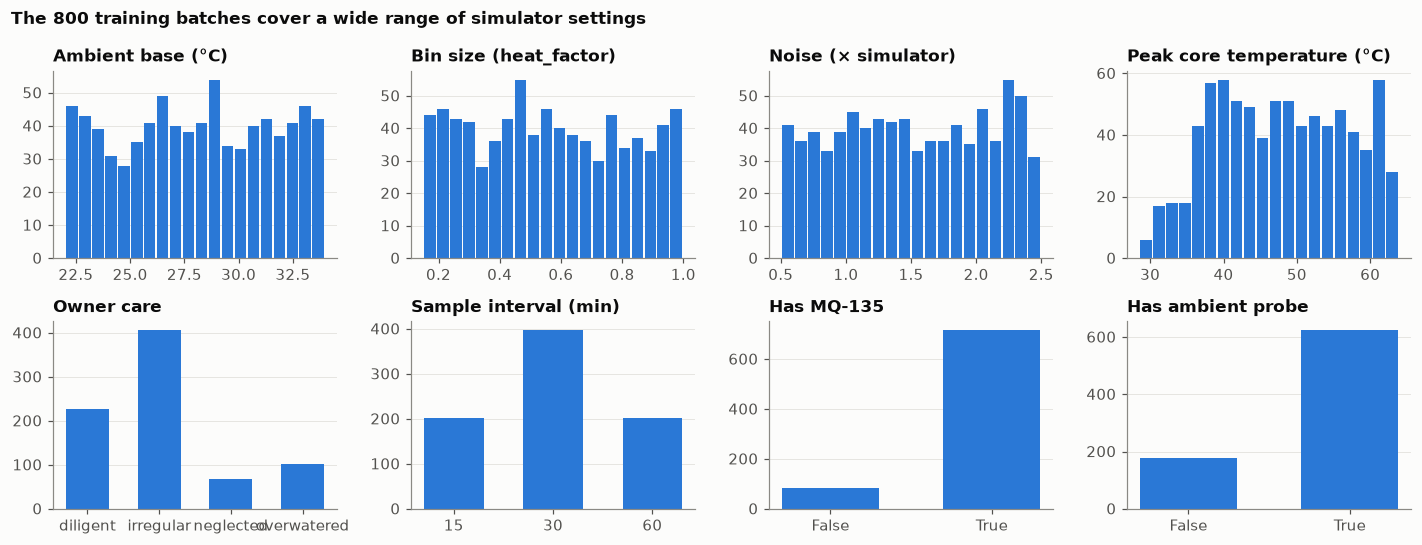

In [3]:
tr = info["train"]
fig, axes = plt.subplots(2, 4, figsize=(13, 5))
numeric = [("ambient_base_c", "Ambient base (°C)"), ("heat_factor", "Bin size (heat_factor)"),
           ("noise_scale", "Noise (× simulator)"), ("peak_temp_c", "Peak core temperature (°C)")]
for ax, (col, label) in zip(axes[0], numeric):
    ax.hist(tr[col], bins=20, color=SERIES[0], rwidth=0.9)
    ax.set_title(label, loc="left")
    ax.grid(axis="x", visible=False)
categorical = [("care", "Owner care"), ("sample_minutes", "Sample interval (min)"),
               ("has_mq135", "Has MQ-135"), ("has_ambient_probe", "Has ambient probe")]
for ax, (col, label) in zip(axes[1], categorical):
    counts = tr[col].astype(str).value_counts().sort_index()
    ax.bar(counts.index, counts.values, color=SERIES[0], width=0.6)
    ax.set_title(label, loc="left")
    ax.grid(axis="x", visible=False)
fig.suptitle(f"The {len(tr)} training batches cover a wide range of simulator settings", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
savefig(fig, "01_training_coverage.png")
plt.show()

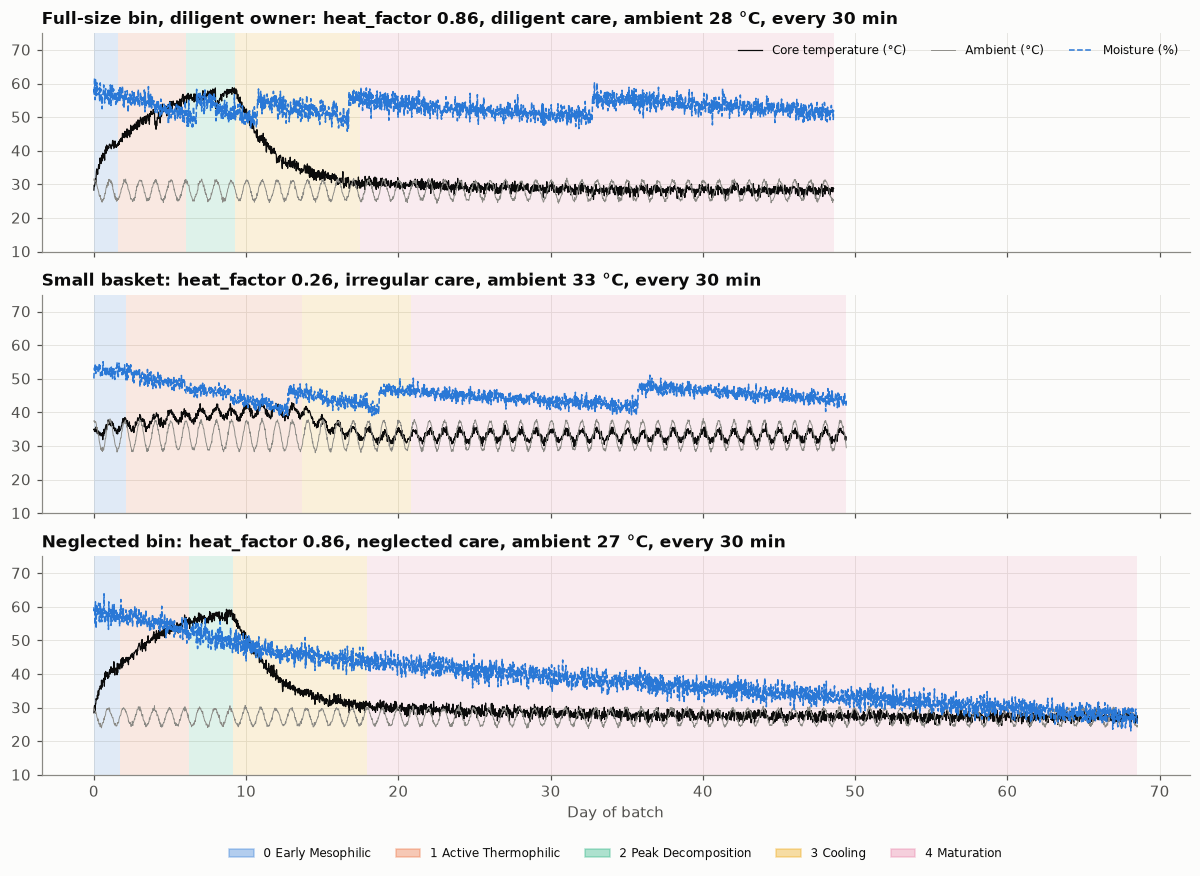

In [4]:
def shade_stages(ax, hours, stages):
    days, stages = np.asarray(hours) / 24, np.asarray(stages)
    start = 0
    for i in range(1, len(stages) + 1):
        if i == len(stages) or stages[i] != stages[start]:
            ax.axvspan(days[start], days[min(i, len(days) - 1)], color=STAGE_COLORS[int(stages[start])],
                       alpha=0.13, linewidth=0)
            start = i


def stage_legend(ax, **kw):
    ax.legend(handles=[Patch(color=c, alpha=0.35, label=l) for c, l in zip(STAGE_COLORS, STAGE_LABELS)],
              ncol=5, fontsize=8, **kw)


picks = [("Full-size bin, diligent owner", tr[(tr.heat_factor > 0.85) & (tr.care == "diligent")].iloc[0]),
         ("Small basket", tr[tr.heat_factor < 0.3].iloc[0]),
         ("Neglected bin", tr[tr.care == "neglected"].iloc[0])]
fig, axes = plt.subplots(len(picks), 1, figsize=(11, 8), sharex=True)
for ax, (label, b) in zip(axes, picks):
    r = raw["train"][raw["train"].batch_id == b.batch_id]
    shade_stages(ax, r.elapsed_h, r.stage_id)
    ax.plot(r.elapsed_h / 24, r.temperature_c, color=INK, lw=0.8, label="Core temperature (°C)")
    if r.ambient_c.notna().any():
        ax.plot(r.elapsed_h / 24, r.ambient_c, color=MUTED, lw=0.6, label="Ambient (°C)")
    ax.plot(r.elapsed_h / 24, r.moisture_pct, color=SERIES[0], lw=1.0, ls="--", label="Moisture (%)")
    ax.set_title(f"{label}: heat_factor {b.heat_factor:.2f}, {b.care} care, ambient {b.ambient_base_c:.0f} °C, "
                 f"every {b.sample_minutes} min", loc="left")
    ax.set_ylim(10, 75)
axes[0].legend(loc="upper right", ncol=3, fontsize=8)
stage_legend(axes[-1], loc="upper center", bbox_to_anchor=(0.5, -0.28))
axes[-1].set_xlabel("Day of batch")
fig.tight_layout()
savefig(fig, "02_example_batches.png")
plt.show()

### 3.1 Two checks on the simulator

**Do the gases still give the label away?** The first version of this notebook found that O₂, CO₂ and
NH₃ jumped at the exact moment the stage changed. The chart averages each signal around every stage
change in the training data. All three should now change smoothly.

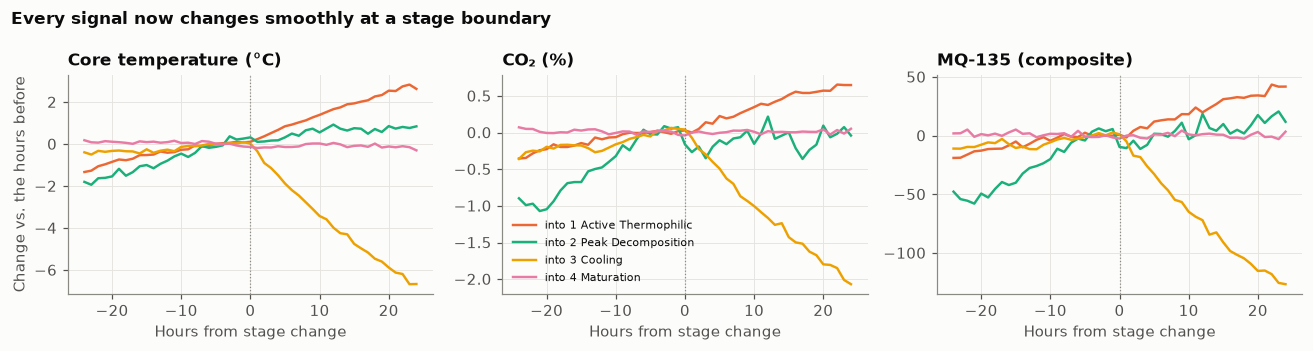

In [5]:
def around_transitions(frame, column, window_h=24):
    traces = {}
    for _, b in frame.groupby("batch_id"):
        b = b.set_index("elapsed_h")
        for t in b.index[b.stage_id.diff().fillna(0) != 0]:
            seg = b.loc[t - window_h:t + window_h, column].dropna()
            before = seg.loc[:t].iloc[-12:-1]
            if len(before) < 3:
                continue
            seg = seg.groupby(((seg.index - t) // 1)).mean()        # hourly, so 15/30/60-minute batches line up
            traces.setdefault(int(b.loc[t, "stage_id"]), []).append(seg - before.mean())
    return {s: pd.concat(v, axis=1).mean(axis=1).sort_index() for s, v in traces.items()}


sample = raw["train"][raw["train"].batch_id.isin(info["train"].batch_id[:150])]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharex=True)
for ax, (column, label) in zip(axes, [("temperature_c", "Core temperature (°C)"), ("co2_pct", "CO₂ (%)"),
                                     ("mq135", "MQ-135 (composite)")]):
    for stage, trace in sorted(around_transitions(sample, column).items()):
        ax.plot(trace.index, trace.values, color=STAGE_COLORS[stage], label=f"into {STAGE_LABELS[stage]}")
    ax.axvline(0, color=MUTED, lw=0.8, ls=":")
    ax.set_title(label, loc="left")
    ax.set_xlabel("Hours from stage change")
axes[0].set_ylabel("Change vs. the hours before")
axes[1].legend(fontsize=7.5, loc="lower left")
fig.suptitle("Every signal now changes smoothly at a stage boundary", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
savefig(fig, "03_transition_check.png")
plt.show()

**What happens to a dried-out pile?** The simulator now reports a pile below 40 % moisture as a
`dry_pile` fault, and below 30 % as `stalled_pile`, instead of letting it pass for Cooling. The table
shows how much of each stage's data carries a fault. Dry piles still happen (neglected bins), but they
are now flagged rather than hidden inside a stage.

In [6]:
r = raw["train"]
faults = r.assign(dry=r.faults.fillna("").str.contains("dry_pile"), stalled=r.faults.fillna("").str.contains("stalled"))
fault_table = faults.groupby("stage_id")[["dry", "stalled"]].mean()
fault_table.index = STAGE_LABELS
fault_table.columns = ["dry_pile (< 40 %)", "stalled_pile (< 30 %)"]
fault_table.style.format("{:.0%}")

,dry_pile (< 40 %),stalled_pile (< 30 %)
0 Early Mesophilic,0%,0%
1 Active Thermophilic,3%,2%
2 Peak Decomposition,1%,0%
3 Cooling,21%,15%
4 Maturation,19%,11%


## 4. Features

`ml/features.py` averages the readings onto a 30-minute grid, carries short gaps forward and
emits one row per hour. Every feature uses only past readings, so the same code can run live.

| Group | Features | Why (section 1) |
|---|---|---|
| Level and trend | `temp`, `temp_mean_6h/24h`, `temp_slope_6h/24h`, `temp_std_24h` | Phase bands; heating vs. cooling at the same temperature |
| Peak memory | `temp_peak`, `below_peak`, `hours_since_peak` | Cooling and curing come *after* the peak |
| Sanitisation | `hours_above_45`, `hours_above_55`, `hours_above_55_run` | Thermophilic onset; the PFRP time-at-temperature rule that now defines stage 2 |
| Moisture | `moist`, `moist_mean_24h`, `moist_slope_24h` | 40–60 % working range; drying tracks the hot phase |
| Ambient | `ambient_known`, `amb_mean_24h`, `dT`, `dT_mean_24h`, `dT_peak` | Maturity means "back to ambient". `ambient_known` = 0 when there's no probe and 28 °C is assumed |
| Scale-free | `frac_of_peak(_24h)`, `slope_rel_6h/24h`, `std_rel_24h` | Heat as a fraction of the bin's own peak, so baskets and piles look alike |
| MQ-135 | `mq135_mean_6h/24h`, `mq135_slope_24h` | Qualitative gas trend (NaN when there's no sensor) |

In [7]:
t0 = time.time()
feats = {name: F.make_features(raw[name]) for name in SPLITS}
train, val, test = feats["train"], feats["validation"], feats["test_grid"]
scenario_of = info["test_grid"].set_index("batch_id").scenario
test = test.assign(scenario=test.batch_id.map(scenario_of))
print(f"features in {time.time() - t0:.0f}s:", {k: len(v) for k, v in feats.items()})
train.groupby("stage_id")[["temp_mean_24h", "hours_above_55_run", "hours_since_peak", "dT_mean_24h",
                           "frac_of_peak", "moist_mean_24h", "mq135_mean_6h"]].median()

features in 11s: {'train': 1030991, 'validation': 264617, 'test_grid': 414507}


,temp_mean_24h,hours_above_55_run,hours_since_peak,dT_mean_24h,frac_of_peak,moist_mean_24h,mq135_mean_6h
stage_id,,,,,,,
0,33.358,0.0,0.0,4.800,0.965,57.759,159.667
1,41.258,0.0,6.0,13.104,0.910,53.996,260.958
2,57.466,34.0,6.5,28.640,0.947,52.360,557.083
3,32.640,0.0,125.5,4.144,0.192,50.471,129.833
4,28.713,0.0,609.5,0.181,0.036,50.421,95.667


## 5. Evaluation protocol

- **Split by batch.** Neighbouring hourly rows from one bin are nearly identical, so a random row split
  puts near-copies of the test rows into training. Every score here comes from batches the model
  never saw.
- **Macro-F1** averages over the five stages, so short stages count as much as Maturation.

The cell below shows how much a random split flatters the score, both with all the training batches
and with only 3, the size of the real pilot.

In [8]:
FEATS = F.FEATURE_SETS["all hardware + MQ-135"]


def quick_gb():
    return HistGradientBoostingClassifier(max_iter=60, learning_rate=0.2, max_leaf_nodes=15,
                                          class_weight="balanced", random_state=SEED)


cv_rows = train[train.elapsed_h % 4 == 0]
random_split = cross_val_score(quick_gb(), cv_rows[FEATS], cv_rows.stage_id, scoring="f1_macro",
                               cv=KFold(4, shuffle=True, random_state=SEED)).mean()
by_batch = cross_val_score(quick_gb(), cv_rows[FEATS], cv_rows.stage_id, groups=cv_rows.batch_id,
                           scoring="f1_macro", cv=GroupKFold(4)).mean()
print(f"{train.batch_id.nunique()} batches — random row split: {random_split:.3f}   split by batch: {by_batch:.3f}")

pilot = train[train.batch_id.isin(train.batch_id.unique()[:3])]
promised = cross_val_score(quick_gb(), pilot[FEATS], pilot.stage_id, scoring="f1_macro",
                           cv=KFold(4, shuffle=True, random_state=SEED)).mean()
delivered = f1_score(val.stage_id, quick_gb().fit(pilot[FEATS], pilot.stage_id).predict(val[FEATS]), average="macro")
print(f"3 pilot bins — random row split promises {promised:.3f}; on {val.batch_id.nunique()} unseen batches it scores {delivered:.3f}")

800 batches — random row split: 0.948   split by batch: 0.917


3 pilot bins — random row split promises 0.992; on 200 unseen batches it scores 0.771


## 6. How the exported model was chosen

`ml/train.py` ran these iterations on the 200 validation batches and wrote every number to
`ml/models/model_card.json`. The cells below read them back rather than re-running them.

1. **Feature sets:** which sensors earn their place.
2. **Gradient-boosting settings:** a small grid.
3. **Learning curve:** how much data is enough. This uses a larger local pool of up to 1,600 batches.
4. **Stage filter:** how fast stages may advance, and how readily stage 1 skips straight to Cooling.

Every fit stops early once the validation loss stops improving. Section 10 explains why that matters.

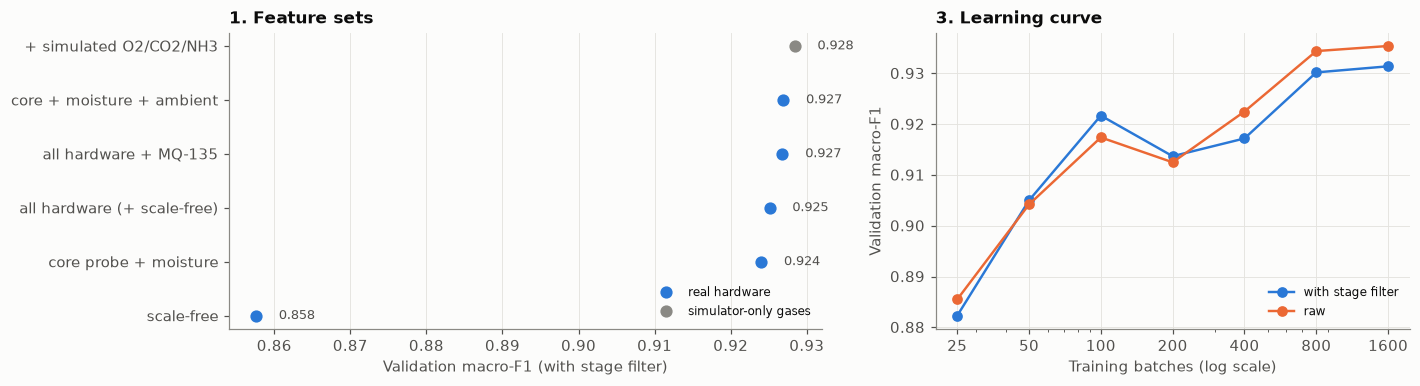

chosen: core + moisture + ambient | lr 0.1, 63 leaves | 48 trees | filter speed 8.0 skip share 0.9


,trees,raw,filtered,fit seconds
settings,,,,
"lr 0.1, 31 leaves",49,0.930,0.924,15
"lr 0.05, 31 leaves",83,0.931,0.925,27
"lr 0.1, 63 leaves",48,0.934,0.930,22
"lr 0.1, 15 leaves",64,0.926,0.921,16
"lr 0.1, 31 leaves, 200 rows per leaf, l2 1.0",53,0.929,0.923,18
"lr 0.1, 31 leaves, every 2nd hour",49,0.932,0.927,12
"lr 0.1, 31 leaves, every 3rd hour",57,0.932,0.927,13


,speed,skip share,filtered
filter,,,
"speed 8, skip 0.9",8.0,0.9,0.934
"speed 8, skip 0.8",8.0,0.8,0.934
"speed 8, skip 0.6",8.0,0.6,0.934
"speed 8, skip 0.4",8.0,0.4,0.934
"speed 8, skip 0.2",8.0,0.2,0.934
"speed 4, skip 0.9",4.0,0.9,0.933
"speed 4, skip 0.8",4.0,0.8,0.933
"speed 4, skip 0.4",4.0,0.4,0.933


In [9]:
card = json.loads((MODELS / "model_card.json").read_text())
exp = {k: pd.DataFrame(v) for k, v in card["experiments"].items()}

fs = exp["feature_sets"].set_index("feature set").sort_values("filtered")
lc = exp["learning_curve"].set_index("training batches")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1.25, 1]})
y = np.arange(len(fs))
usable = np.array(["simulated" not in n for n in fs.index])
for keep, color, label in [(usable, SERIES[0], "real hardware"), (~usable, MUTED, "simulator-only gases")]:
    ax1.plot(fs.filtered[keep], y[keep], "o", ms=7, color=color, label=label)
for yi, v in zip(y, fs.filtered):
    ax1.text(v + 0.003, yi, f"{v:.3f}", va="center", fontsize=8.5, color=INK_2)
ax1.set_yticks(y, fs.index)
ax1.set_xlabel("Validation macro-F1 (with stage filter)")
ax1.set_title("1. Feature sets", loc="left")
ax1.legend(loc="lower right", fontsize=8)
ax1.grid(axis="y", visible=False)
ax2.plot(lc.index, lc.filtered, marker="o", color=SERIES[0], label="with stage filter")
ax2.plot(lc.index, lc.raw, marker="o", color=SERIES[1], label="raw")
ax2.set_xscale("log")
ax2.set_xticks(lc.index, [str(i) for i in lc.index])
ax2.set_xlabel("Training batches (log scale)")
ax2.set_ylabel("Validation macro-F1")
ax2.set_title("3. Learning curve", loc="left")
ax2.legend(loc="lower right", fontsize=8)
fig.tight_layout()
savefig(fig, "04_model_selection.png")
plt.show()

print("chosen:", card["feature_set"], "|", card["settings_name"], f"| {card['settings']['max_iter']} trees |",
      "filter speed", card["stage_filter_speed"], "skip share", card["stage_filter_skip_share"])
display(exp["hyperparameters"].set_index("settings"))
exp["filter"].set_index("filter").sort_values("filtered", ascending=False).head(8)

## 7. Four models on the same data

1. **Literature rules (no training).** Thresholds from section 1: past 45 °C means thermophilic, holding
   ≥ 55 °C for 6 h means Peak Decomposition, still more than 5 °C above ambient after the peak means
   Cooling, and otherwise Maturation.
2. **Decision tree:** small enough for the ESP32. It's tuned by batch-grouped CV, and we keep the
   shallowest depth within 0.02 of the best.
3. **Gradient boosting:** the exported model from `ml/models/`, trained by `train.py` on train +
   validation, with its stage filter.
4. **GRU (PyTorch):** reads the hourly readings in order and keeps its own memory. To keep the run
   short it trains on 160 of the 800 training batches.

In [10]:
def rule_based_stage(f):
    near_peak = f["below_peak"] < 3.0
    return np.select(
        [f["temp_peak"] < 45,                      # never got past mesophilic
         f["hours_above_55_run"] >= 6,             # holding >= 55 C: the PFRP band
         near_peak,                                # still climbing through the hot phase
         f["dT_mean_24h"] > 5.0],                  # past the peak, still clearly above ambient
        [0, 2, 1, 3], default=4)


t0 = time.time()
tree_rows = train[train.elapsed_h % 4 == 0]                 # every 4th hour keeps the search quick
tree_search = GridSearchCV(DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
                           {"max_depth": [4, 5, 6, 8, 10, 12], "min_samples_leaf": [50, 200]},
                           cv=GroupKFold(3), scoring="f1_macro")
tree_search.fit(tree_rows[FEATS], tree_rows.stage_id, groups=tree_rows.batch_id)
grid = pd.DataFrame(tree_search.cv_results_)
best = grid.mean_test_score.max()
pick = grid[grid.mean_test_score >= best - 0.02].sort_values(["param_max_depth", "param_min_samples_leaf"],
                                                             ascending=[True, False]).iloc[0]
tree = DecisionTreeClassifier(class_weight="balanced", random_state=SEED, max_depth=int(pick.param_max_depth),
                              min_samples_leaf=int(pick.param_min_samples_leaf)).fit(train[FEATS], train.stage_id)
print(f"decision tree: depth {tree.get_depth()}, {tree.get_n_leaves()} leaves "
      f"(CV {pick.mean_test_score:.3f}, best {best:.3f}) in {time.time() - t0:.0f}s")

bundle = load_model(MODELS / "compost_stage_gb.joblib")
gb_pred = predict_features(bundle, test)
print(f"exported gradient boosting: {bundle['feature_set']}, {len(bundle['features'])} features, "
      f"scikit-learn {bundle['sklearn_version']}")

decision tree: depth 5, 26 leaves (CV 0.889, best 0.906) in 96s


exported gradient boosting: core + moisture + ambient, 20 features, scikit-learn 1.9.1


In [11]:
import torch
from torch import nn

torch.manual_seed(SEED)
torch.set_num_threads(max(1, (os.cpu_count() or 2) // 2))
SEQ_COLS = ["temp", "moist", "amb_mean_24h", "ambient_known", "mq135_mean_6h"]
gru_train = train[train.batch_id.isin(train.batch_id.unique()[:160])]
mu, sd = gru_train[SEQ_COLS].mean(), gru_train[SEQ_COLS].std()


def to_sequences(frame):
    xs, ys, index = [], [], []
    for idx in frame.groupby("batch_id", sort=False).indices.values():
        g = frame.iloc[idx]
        xs.append(torch.tensor(((g[SEQ_COLS] - mu) / sd).fillna(0.0).to_numpy(np.float32)))
        ys.append(torch.tensor(g.stage_id.to_numpy(np.int64)))
        index.append(idx)
    return xs, ys, index


class StageGRU(nn.Module):
    def __init__(self, n_inputs, hidden=48, n_stages=5):
        super().__init__()
        self.gru = nn.GRU(n_inputs, hidden, num_layers=2, batch_first=True, dropout=0.1)
        self.head = nn.Linear(hidden, n_stages)

    def forward(self, x):
        return self.head(self.gru(x)[0])


def gru_proba(net, frame):
    xs, _, index = to_sequences(frame)
    proba = np.zeros((len(frame), 5), dtype=np.float32)
    net.eval()
    with torch.no_grad():
        for x, idx in zip(xs, index):
            proba[idx] = torch.softmax(net(x[None])[0], dim=-1).numpy()
    return proba


xs, ys, _ = to_sequences(gru_train)
weights = torch.tensor(len(gru_train) / (5 * np.bincount(gru_train.stage_id, minlength=5)), dtype=torch.float32)
net = StageGRU(len(SEQ_COLS))
optimiser = torch.optim.Adam(net.parameters(), lr=3e-3)
loss_fn = nn.CrossEntropyLoss(weight=weights, ignore_index=-100)
val_small = val[val.batch_id.isin(val.batch_id.unique()[:40])]
best_f1, best_state, t0 = -1.0, None, time.time()
for epoch in range(20):
    net.train()
    for pick_ in torch.randperm(len(xs)).split(8):
        X = nn.utils.rnn.pad_sequence([xs[i] for i in pick_], batch_first=True)
        Y = nn.utils.rnn.pad_sequence([ys[i] for i in pick_], batch_first=True, padding_value=-100)
        loss = loss_fn(net(X).reshape(-1, 5), Y.reshape(-1))
        optimiser.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(net.parameters(), 1.0)
        optimiser.step()
    f1 = f1_score(val_small.stage_id, gru_proba(net, val_small).argmax(1), average="macro")
    if f1 > best_f1:
        best_f1, best_state = f1, {k: v.clone() for k, v in net.state_dict().items()}
net.load_state_dict(best_state)
print(f"GRU trained in {time.time() - t0:.0f}s; best validation macro-F1 {best_f1:.3f}")

GRU trained in 135s; best validation macro-F1 0.926


## 8. The test grid: every model, every simulator setting

Each cell below is the macro-F1 on 15 unseen batches for one scenario, where one simulator setting is
changed from the baseline. For gradient boosting the cell scores what a dashboard would show: the
prediction after the stage filter.

,macro-F1,balanced acc.,worst scenario
Literature rules,0.660,0.738,0.020
Decision tree (ESP32),0.904,0.928,0.840
GRU (PyTorch),0.915,0.937,0.854
Gradient boosting + filter (exported),0.945,0.959,0.917


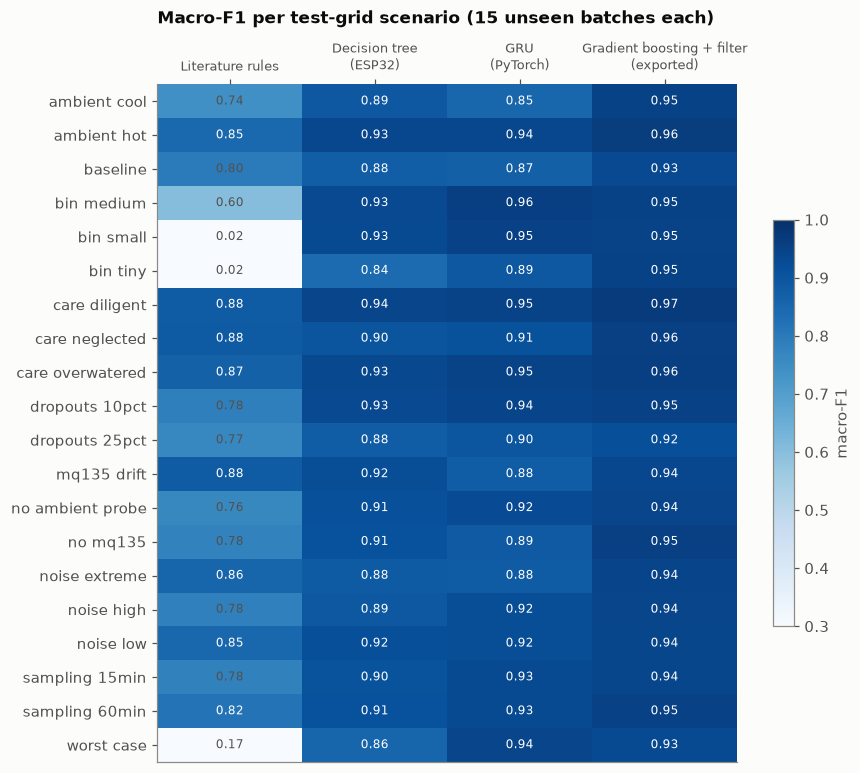

In [12]:
proba_gru = gru_proba(net, test)
predictions = {
    "Literature rules": rule_based_stage(test),
    "Decision tree (ESP32)": tree.predict(test[FEATS]),
    "GRU (PyTorch)": proba_gru.argmax(1),
    "Gradient boosting + filter (exported)": gb_pred.stage_id_filtered.to_numpy(),
}
by_scenario = pd.DataFrame({
    name: pd.Series(pred, index=test.index).groupby(test.scenario, sort=False)
          .apply(lambda p: f1_score(test.stage_id[p.index], p, average="macro"))
    for name, pred in predictions.items()
})
overall = pd.DataFrame({name: {"macro-F1": f1_score(test.stage_id, p, average="macro"),
                               "balanced acc.": balanced_accuracy_score(test.stage_id, p),
                               "worst scenario": by_scenario[name].min()}
                        for name, p in predictions.items()}).T
display(overall)

fig, ax = plt.subplots(figsize=(8.5, 8))
im = ax.imshow(by_scenario.values, cmap="Blues", vmin=0.3, vmax=1.0, aspect="auto")
for i in range(by_scenario.shape[0]):
    for j in range(by_scenario.shape[1]):
        v = by_scenario.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.8 else INK_2)
ax.set_xticks(range(by_scenario.shape[1]), [c.replace(" (", "\n(") for c in by_scenario.columns], fontsize=8.5)
ax.set_yticks(range(by_scenario.shape[0]), [s.replace("_", " ") for s in by_scenario.index])
ax.xaxis.tick_top()
ax.grid(False)
per_cell = int(test.groupby("scenario").batch_id.nunique().median())
ax.set_title(f"Macro-F1 per test-grid scenario ({per_cell} unseen batches each)", loc="left", pad=40)
fig.colorbar(im, ax=ax, shrink=0.6, label="macro-F1")
savefig(fig, "05_test_grid_heatmap.png")
plt.show()

stage changes per batch — truth 3.8, gradient boosting raw 9.4, filtered 4.2, GRU 4.5


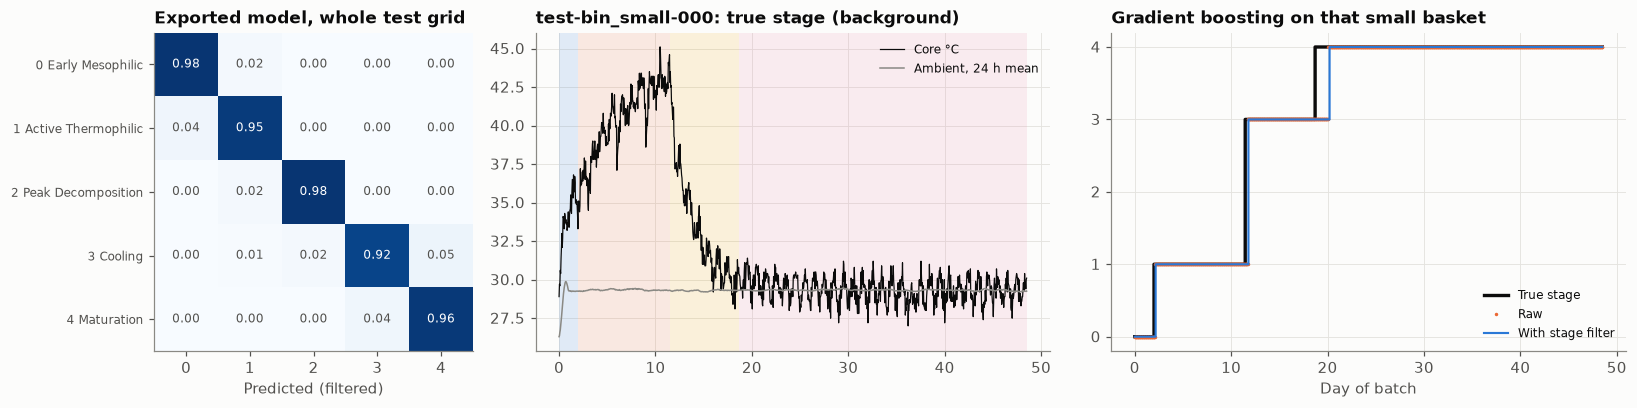

In [13]:
cm = confusion_matrix(test.stage_id, gb_pred.stage_id_filtered, labels=STAGE_IDS, normalize="true")
flips = lambda pred: pd.Series(pred).groupby(test.batch_id.values).apply(lambda s: int((s.diff().fillna(0) != 0).sum())).mean()
print(f"stage changes per batch — truth {flips(test.stage_id.values):.1f}, gradient boosting raw "
      f"{flips(gb_pred.predicted_stage_id.values):.1f}, filtered {flips(gb_pred.stage_id_filtered.values):.1f}, "
      f"GRU {flips(proba_gru.argmax(1)):.1f}")

batch_id = info["test_grid"].query("scenario == 'bin_small'").batch_id.iloc[0]
m = (test.batch_id == batch_id).to_numpy()
b = test[m]
fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1, 1.6, 1.6]})
ax0.imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(5):
    for j in range(5):
        ax0.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 0.6 else INK_2)
ax0.set_xticks(STAGE_IDS, [str(i) for i in STAGE_IDS])
ax0.set_yticks(STAGE_IDS, STAGE_LABELS, fontsize=8)
ax0.set_xlabel("Predicted (filtered)")
ax0.set_title("Exported model, whole test grid", loc="left")
ax0.grid(False)
shade_stages(ax1, b.elapsed_h, b.stage_id)
ax1.plot(b.elapsed_h / 24, b.temp, color=INK, lw=0.8, label="Core °C")
ax1.plot(b.elapsed_h / 24, b.amb_mean_24h, color=MUTED, lw=1, label="Ambient, 24 h mean")
ax1.set_title(f"{batch_id}: true stage (background)", loc="left")
ax1.legend(fontsize=8, loc="upper right")
ax2.step(b.elapsed_h / 24, b.stage_id, where="post", color=INK, lw=2.2, label="True stage")
ax2.plot(b.elapsed_h / 24, gb_pred.predicted_stage_id.to_numpy()[m], ".", ms=2.5, color=SERIES[1], label="Raw")
ax2.step(b.elapsed_h / 24, gb_pred.stage_id_filtered.to_numpy()[m], where="post", color=SERIES[0], lw=1.4, label="With stage filter")
ax2.set_yticks(STAGE_IDS, [str(i) for i in STAGE_IDS])
ax2.set_xlabel("Day of batch")
ax2.set_title("Gradient boosting on that small basket", loc="left")
ax2.legend(fontsize=8, loc="lower right")
fig.tight_layout()
savefig(fig, "06_exported_model.png")
plt.show()

## 9. Export for the ESP32

The production model is the gradient boosting bundle in `ml/models/` (`train.py` writes it, and
`predict.py` reads any CSV with it). For the logger itself, the decision tree is written out as a plain
C function. It needs a 24 h ring buffer of readings plus the running peak and counters, all described
in `ml/features.py`.

ml/outputs/compost_stage_tree.h: 97 lines


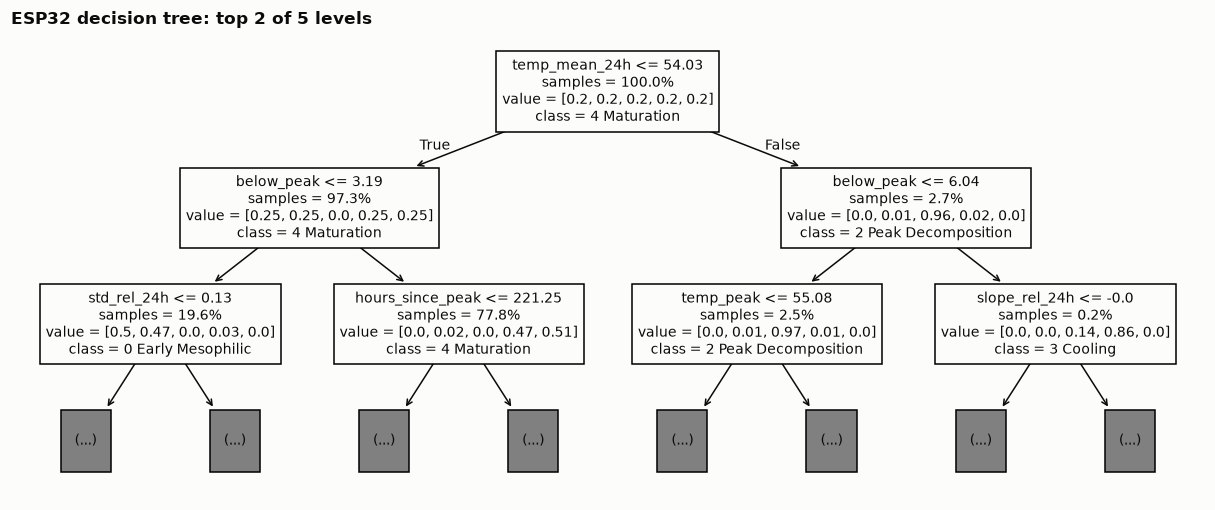

In [14]:
def tree_to_c(model, feature_names, function="compost_stage"):
    t = model.tree_
    lines = ["// Generated by ml/compost_stage_classifier.ipynb. Do not edit by hand.",
             "// Returns the compost stage id: " + ", ".join(STAGE_LABELS),
             "// Feature definitions: ml/features.py. f[] holds them in this order:"]
    lines += [f"//   f[{i:2d}] {name}" for i, name in enumerate(feature_names)]
    lines += ["#pragma once", "", f"static inline int {function}(const float *f) {{"]

    def stages_below(node):
        if t.children_left[node] == -1:
            return {int(np.argmax(t.value[node]))}
        return stages_below(t.children_left[node]) | stages_below(t.children_right[node])

    def walk(node, depth):
        pad = "    " * depth
        stages = stages_below(node)
        if len(stages) == 1:
            stage = stages.pop()
            lines.append(f"{pad}return {stage};  // {STAGE_NAMES[stage]}")
            return
        i = t.feature[node]
        # a missing value (NaN, e.g. no MQ-135) goes the way scikit-learn sends it
        nan_left = bool(t.missing_go_to_left[node]) if hasattr(t, "missing_go_to_left") else True
        test_expr = (f"(isnan(f[{i}]) || f[{i}] <= {t.threshold[node]:.4f}f)" if nan_left
                     else f"(!isnan(f[{i}]) && f[{i}] <= {t.threshold[node]:.4f}f)")
        lines.append(f"{pad}if {test_expr} {{  // {feature_names[i]}")
        walk(t.children_left[node], depth + 1)
        lines.append(f"{pad}}} else {{")
        walk(t.children_right[node], depth + 1)
        lines.append(f"{pad}}}")

    walk(0, 1)
    lines.append("}")
    return "#include <math.h>\n" + "\n".join(lines) + "\n"


header = tree_to_c(tree, FEATS)
(OUT / "compost_stage_tree.h").write_text(header)
print(f"ml/outputs/compost_stage_tree.h: {header.count(chr(10))} lines")
fig, ax = plt.subplots(figsize=(14, 5.5))
plot_tree(tree, max_depth=2, feature_names=FEATS, class_names=STAGE_LABELS, filled=False, impurity=False,
          proportion=True, precision=2, fontsize=9, ax=ax)
ax.set_title(f"ESP32 decision tree: top 2 of {tree.get_depth()} levels", loc="left")
savefig(fig, "07_decision_tree.png")
plt.show()

## 10. Conclusions and recommendations

### What to use
- **Server and dashboard:** use `ml/models/compost_stage_gb.joblib` through `ml/predict.py` (the command line, or `predict_readings()` from Python) and show `stage_filtered`. Re-run `python ml/train.py` whenever the simulator or the data changes. It takes about 7 minutes and rewrites the model, `model_card.json` and `TRAINING_REPORT.md`.
- **ESP32:** `ml/outputs/compost_stage_tree.h` is a depth-5 tree. It scores 0.904 overall and at least 0.84 in every scenario. Use it as an offline fallback on the logger, not as a replacement for the server model.
- **GRU:** it reads raw readings and is steady without a filter, but it scores below gradient boosting at much higher cost. Keep it as research.

### Hardware
- **Ambient probe:** a second DS18B20 on the existing 1-Wire bus is cheap, and the literature defines maturity relative to ambient. The model no longer depends on one, though. The `ambient_known` feature tells it when 28 °C is only assumed, and it scores 0.94 in the `no_ambient_probe` scenario.
- **MQ-135:** it shows no measurable benefit in simulation. That's partly by construction, because the simulator builds its signal from CO₂ and NH₃, which follow the same activity curve as temperature. Keep it only if real pilot data shows it adds something the probes miss, such as ammonia from a wet, anaerobic pile.
- **Moisture sensor:** calibrate it against weighed samples of the actual feedstock. Moisture is one of the three signals the model relies on.

### Data
- **Size:** the committed CSVs are about 41 MB. The learning curve says the 800-batch training set is enough: doubling it to 1,600 added 0.001.
- **Rebuilding:** every file can be rebuilt exactly with `ml/dataset.py`, because each batch has its own seed.
- **Weakest scenarios:** 25 % missed readings (0.917), the combined worst case (0.928) and the baseline (0.930). With 15 batches per scenario, differences under about 0.02 are noise.

### Next steps
1. **Label the pilot batches.** For each one, record the date of peak temperature, when cooling starts and a maturity check. Then score the exported model leave-one-bin-out. Section 5 shows why a random split would mislead with three bins.
2. **Check against reality:** compare real Takakura temperature curves with the simulator's `heat_factor` range (Nurita 2023 reports peaks near 35 °C) before trusting small-basket scores.
3. **Fold real data into training:** once real batches exist, add them to `train.py` alongside the simulated ones, and keep the simulator's test grid as a regression check.

### Limitations
- **Labels:** every label comes from the simulator's stage rules, so these scores show how well a model recovers those rules, not compost biology.
- **Assumptions:** the ambient swing, core heat leakage, owner behaviour and MQ-135 drift are assumptions layered on the pile model, not measurements.

## References

Sources marked † were checked only through the abstract or a search snippet.

- **Standards**
  - [US EPA 40 CFR 503, Appendix B](https://www.law.cornell.edu/cfr/text/40/appendix-B_to_part_503): PFRP / PSRP time-temperature rules
  - [EU 2019/1009, Annex II (CMC 3)](https://www.legislation.gov.uk/eur/2019/1009/annex/II/2020-01-31): compost sanitisation and stability
  - [NSW EPA 2016, garden organics](https://www.epa.nsw.gov.au/sites/default/files/rro16-garden-organics.pdf): references AS 4454-2012
- **Extension guidance**
  - [Cornell Waste Management Institute: compost microorganisms](https://compost.css.cornell.edu/microorg.html)
  - [Cornell FS4: oxygen](https://www.compost.css.cornell.edu/Factsheets/FS4.html)
  - [Cornell: monitoring moisture](https://www.compost.css.cornell.edu/monitor/monitormoisture.html)
  - [CCE Tompkins: compost testing](https://ccetompkins.org/resources/compost-testing-for-finished-compost)
  - [LSU AgCenter: basic principles of composting](https://agsci.oregonstate.edu/sites/agscid7/files/snic/basic-principles-of-composting-lsu.pdf)
- **Process and maturity**
  - [Solvita compost test manual](https://projects.sare.org/media/pdf/9/8/2/982665solvita-compost-test-manual.pdf)
  - [Cabañas-Vargas et al. 2005](https://www.revista.ingenieria.uady.mx/volumen9/assessing.pdf): windrow temperatures, Dewar self-heating
  - [Huang et al. 2017, PLOS ONE](https://pmc.ncbi.nlm.nih.gov/articles/PMC5467826/): maturity criteria
  - [Pagans et al. 2006, Chemosphere](https://ddd.uab.cat/pub/artpub/2006/163578/chemosphere_a2006m3v62n9p1534.pdf) †: NH₃ emission vs. temperature
  - [Jackson & Line 1998](https://eprints.utas.edu.au/11434/) †: windrow O₂ and the CO₂/O₂ quotient
  - [Lim et al. 2017, CET](https://www.aidic.it/cet/17/61/173.pdf): in-vessel curing, small loads
- **Takakura and bokashi**
  - [Nurita et al. 2023](https://ojs.poltekkesbengkulu.ac.id/index.php/sanpro/article/download/383/236): Takakura temperature profile, Indonesia
  - [Larasati 2019](https://ikesma.journal.unej.ac.id/article/view/14156/): Takakura temperatures
  - [Polinema IoT Takakura](https://jartel.polinema.ac.id/index.php/jartel/article/view/533) †
  - [Campos-Rodríguez 2016](https://revistas.tec.ac.cr/index.php/tec_marcha/article/view/2982)
  - [UniKL indoor composter](https://ir.unikl.edu.my/jspui/handle/123456789/7114) †
  - [FEMS Microbes 2026](https://doi.org/10.1093/femsmc/xtag018): bokashi microbiology
  - [Lew et al. 2021](https://pmc.ncbi.nlm.nih.gov/articles/PMC8073414/): smart bokashi bin
- **Sensors**
  - [Hanwei MQ-135 datasheet](https://cdn.shopify.com/s/files/1/2132/9029/files/MQ-135.pdf)
  - [Winsen MQ-135 manual](https://www.winsen-sensor.com/manual/mq135.html)
- **Machine learning and evaluation**
  - [Ma et al. 2025, CET](https://www.cetjournal.it/cet/25/122/004.pdf): GMM phase mapping + AutoML
  - [Wei et al. 2022](https://redi.cedia.edu.ec/document/529930) †: compost maturity regression
  - [Ding et al. 2022](https://agris.fao.org/search/en/records/65de2dba4c5aef494fdaa336) †
  - [Aydın Temel et al. 2023 review](https://avesis.marmara.edu.tr/yayin/ea694acd-5383-4689-8a80-3e7238935798/artificial-intelligence-and-machine-learning-approaches-in-composting-process-a-review) †
  - [Huang et al. 2024, Waste Management](https://doi.org/10.1016/j.wasman.2024.02.022) †
  - [Roberts et al. 2017, Ecography](https://www.biometrie.uni-freiburg.de/mitarbeiter/dormann/roberts-et-al-2017-ecography.pdf): blocked cross-validation
  - [Kapoor & Narayanan 2023](https://ar5iv.labs.arxiv.org/html/2207.07048): leakage in ML-based science